# Лабораторная работа № 1
## Иерархическая кластеризация. Леденцы

Нужно разделить потребителей леденцов на группы по причинам их употребления, выбрать число кластеров и объяснить, чем полученные группы отличаются друг от друга.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 15)

### 1. Данные

Одна строка - ответы одного респондента. Признаки V1–V11 показывают, насколько он согласен с разными причинами употребления леденцов:

| Признак | Причина |
|---|---|
| V1 | Освежить дыхание |
| V2 | Чувствовать себя увереннее |
| V3 | Освежить полость рта |
| V4 | Избавиться от неприятного вкуса |
| V5 | Заменить другие кондитерские изделия |
| V6 | Съесть что-нибудь сладкое |
| V7 | Сконцентрироваться |
| V8 | Отвлечься и подумать |
| V9 | Облегчить боль в горле |
| V10 | Избавиться от заложенности носа |
| V11 | Улучшить самочувствие |

Сначала загрузим таблицу и проверим, есть ли пропуски и повторяющиеся ответы.

In [2]:
data_path = Path("Леденцы.dat")
data = pd.read_csv(data_path, sep=";")

display(data.head())
print("Размер таблицы:", data.shape)
print("Пропуски:", data.isna().sum().sum())
print("Повторные строки:", data.duplicated().sum())
print("Разные профили ответов:", len(data.drop_duplicates()))
print("Значения в таблице:", np.unique(data))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


Размер таблицы: (338, 11)
Пропуски: 0
Повторные строки: 293
Разные профили ответов: 45
Значения в таблице: [2 3 4 5]


В таблице 338 респондентов и 11 признаков, пропусков нет. Оценки принимают значения от 2 до 5. Подписи отдельных баллов в задании не указаны, поэтому, например, называть ответ 3 нейтральным нельзя.

Повторяются 293 строки, но удалять их не будем, так как разные люди могут давать одинаковые ответы. Иначе изменятся размеры и состав групп.

Все вопросы измерены в общей шкале, поэтому используем исходные оценки. При этом считаем разницу в один балл одинаковой на разных участках шкалы. Для оценок согласия это приближение; его нужно учитывать при выводах.

### 2. Как будем выбирать метод и число групп

Заранее фиксировать ни метод, ни число кластеров не будем. Сравним все сочетания четырёх методов и чисел групп от 2 до 10 - всего 36 вариантов. Это диапазон для поиска относительно крупных сегментов, а не проверка всех возможных разбиений.

В агломеративной кластеризации сначала каждый человек образует отдельную группу. Затем группы последовательно объединяются. Методы различаются правилом выбора очередного объединения:

| Метод | Расстояние между группами / правило объединения |
|---|---|
| single | Расстояние между ближайшей парой объектов разных групп |
| complete | Расстояние между самой далёкой парой объектов разных групп |
| average | Среднее расстояние по всем межгрупповым парам |
| Ward | Наименьший прирост суммы квадратов расстояний до центров групп |

Для всех вариантов используем исходные 11 признаков и евклидову метрику. Так сравниваем именно методы и число групп, не меняя одновременно шкалу и расстояние. Ward требует евклидовой геометрии, остальные три метода также допускают эту метрику.

При выборе будем учитывать три вещи:

1. **Разделённость групп:** насколько высок силуэт.
2. **Размеры:** нет ли дробления на очень маленькие подгруппы.
3. **Смысл:** какие различия мы сохраняем или теряем при изменении числа групп.

Цель задания - получить понятные потребительские сегменты. Поэтому силуэт будет первым ориентиром, но не единственным правилом выбора. Жёсткий порог минимального размера вводить не будем. Маленькая группа может быть полезной нишей, если именно такая детализация нужна исследованию.


In [3]:
def fit_clusters(frame, n_clusters, method):
    """Вернуть дерево и метки групп для заданных метода и числа кластеров."""
    if not 2 <= n_clusters < len(frame):
        raise ValueError("Число групп должно быть от 2 до числа объектов минус 1.")
    Z = linkage(frame, method=method, metric="euclidean")
    labels = cut_tree(Z, n_clusters=[n_clusters]).ravel() + 1
    return Z, labels


def compare_k(frame, k_values, method):
    """Сравнить срезы одного дерева: силуэт, размеры и минимальная доля."""
    Z = linkage(frame, method=method, metric="euclidean")
    rows = []
    for k in k_values:
        if not 2 <= k < len(frame):
            raise ValueError("k должно быть от 2 до числа объектов минус 1.")
        labels = cut_tree(Z, n_clusters=[k]).ravel()
        sizes = pd.Series(labels).value_counts().sort_values(ascending=False)
        rows.append({
            "Метод": method,
            "k": k,
            "Силуэт": silhouette_score(frame, labels),
            "Минимальный размер": sizes.min(),
            "Минимальная доля, %": sizes.min() / len(frame) * 100,
            "Размеры групп": "/".join(sizes.astype(str)),
        })
    return pd.DataFrame(rows)

### 3. Сравнение всех вариантов

Построим таблицу и график силуэта для всех 36 сочетаний. Затем для каждого метода найдём его собственное лучшее число групп по этому показателю. На этом шаге окончательное решение ещё не принимается.

Метод,single,complete,average,ward
k,,,,
2,0.455,0.455,0.455,0.455
3,0.374,0.614,0.614,0.614
4,0.560,0.727,0.727,0.727
5,0.463,0.701,0.679,0.698
6,0.671,0.718,0.670,0.729
7,0.656,0.647,0.733,0.731
8,0.603,0.663,0.671,0.744
9,0.624,0.655,0.672,0.645
10,0.603,0.668,0.694,0.659


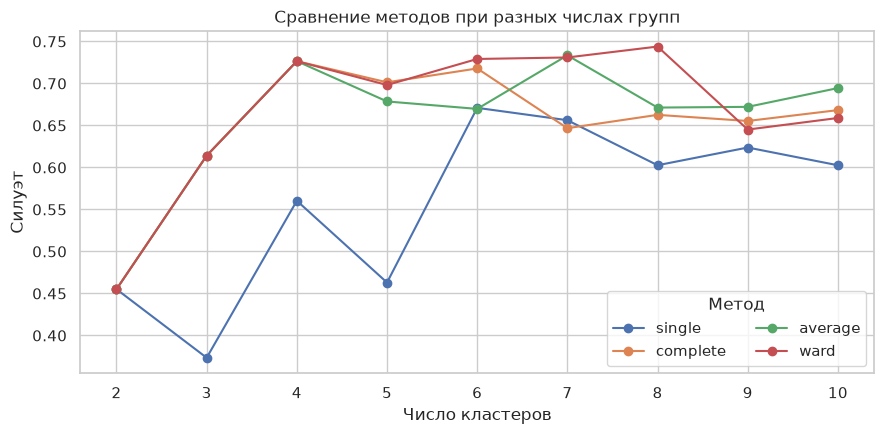

Лучшее число групп по силуэту для каждого метода:


,k,Силуэт,Минимальный размер,"Минимальная доля, %",Размеры групп
Метод,,,,,
single,6,0.671,2,0.592,110/104/61/57/4/2
complete,4,0.727,59,17.456,110/108/61/59
average,7,0.733,4,1.183,110/61/59/59/38/7/4
ward,8,0.744,4,1.183,110/59/59/46/29/16/15/4


In [4]:
methods = ["single", "complete", "average", "ward"]
k_values = range(2, 11)

results = pd.concat([compare_k(data, k_values, method) for method in methods],
                    ignore_index=True)
silhouettes = results.pivot(index="k", columns="Метод", values="Силуэт")[methods]
display(silhouettes)

fig, ax = plt.subplots(figsize=(9, 4.5))
for method in methods:
    ax.plot(silhouettes.index, silhouettes[method], "o-", label=method)
ax.set(xticks=list(k_values), xlabel="Число кластеров", ylabel="Силуэт",
       title="Сравнение методов при разных числах групп")
ax.legend(title="Метод", ncols=2)
plt.tight_layout()
plt.show()

best_indices = results.groupby("Метод", sort=False)["Силуэт"].idxmax()
best_by_method = results.loc[best_indices].set_index("Метод").loc[methods]
print("Лучшее число групп по силуэту для каждого метода:")
display(best_by_method)

По таблице получаются разные ответы:

- **single:** лучший силуэт при 6 группах - 0,6709; среди них есть группы из 4 и 2 человек. Даже лучший результат этого метода ниже лучших результатов остальных методов, поэтому дальше его не выбираем.
- **complete:** максимум при 4 группах - 0,7265; размеры 110, 108, 61 и 59.
- **average:** максимум при 7 группах - 0,7334; минимальные группы содержат 7 и 4 человека.
- **Ward:** максимум при 8 группах - 0,7439; минимальная группа - 4 человека.

**Если выбирать исключительно по силуэту, ответ - Ward и 8 кластеров.** Четыре группы не являются максимумом всей таблицы. У complete они являются максимумом только среди его собственных срезов.

Теперь нужно понять, что дают дополнительные группы. Рассмотрим профили лучшего решения каждого метода по всем 11 вопросам. Прежде чем давать группам названия, объясним, какие темы видны в анкете и почему вопросы одной темы нельзя автоматически заменять одним средним.

**Откуда берутся темы для интерпретации?**

Они предложены по смыслу формулировок, а не заданы как готовые шкалы в условии:

- V1, V3 и V4 относятся к ощущениям во рту: свежести дыхания, освежению рта и устранению неприятного вкуса. V2 об уверенности можно рассматривать рядом, но это отдельный психологический мотив, а не ещё одна формулировка свежести.
- V5 и V6 связаны со сладким: замена других кондитерских изделий и желание съесть что-нибудь сладкое. Это близкие, но не одинаковые причины.
- V7 и V8 относятся к сосредоточению и короткой паузе. «Сконцентрироваться» и «отвлечься и подумать» не синонимы, поэтому сохраняем оба вопроса.
- V9, V10 и V11 связаны с самочувствием: горлом, носом и общим состоянием. Конкретные симптомы и общая оценка состояния также различаются.

Такие темы - рабочие ориентиры для описания ответов. Проверим, сопровождается ли смысловая близость согласованным изменением оценок. Используем корреляцию Спирмена. Она сравнивает ранги и подходит для изучения связи порядковых ответов. В таблице покажем минимум и максимум корреляций всех пар вопросов каждой темы.

In [5]:
themes = {
    "Свежесть и уверенность": ["V1", "V2", "V3", "V4"],
    "Сладкое": ["V5", "V6"],
    "Концентрация и пауза": ["V7", "V8"],
    "Самочувствие": ["V9", "V10", "V11"],
}

# Это проверка связи вопросов, а не создание четырёх новых признаков.
spearman = data.corr(method="spearman")
theme_rows = []
for theme, columns in themes.items():
    pair_correlations = [spearman.loc[first, second]
                         for i, first in enumerate(columns)
                         for second in columns[i + 1:]]
    theme_rows.append({
        "Условная тема": theme,
        "Вопросы": ", ".join(columns),
        "Минимальная корреляция": min(pair_correlations),
        "Максимальная корреляция": max(pair_correlations),
    })
display(pd.DataFrame(theme_rows).set_index("Условная тема"))

,Вопросы,Минимальная корреляция,Максимальная корреляция
Условная тема,,,
Свежесть и уверенность,"V1, V2, V3, V4",0.860,0.977
Сладкое,"V5, V6",0.979,0.979
Концентрация и пауза,"V7, V8",0.868,0.868
Самочувствие,"V9, V10, V11",0.979,0.997


Посмотрим на полную матрицу Спирмена: так видны связи и внутри предложенных тем, и между ними. Красный цвет означает положительную связь, синий - отрицательную, светлый - близкую к нулю. На диагонали всегда 1: каждый вопрос полностью связан с самим собой. Чёрные рамки обозначают обсуждаемые темы, а не группы, найденные отдельным алгоритмом.

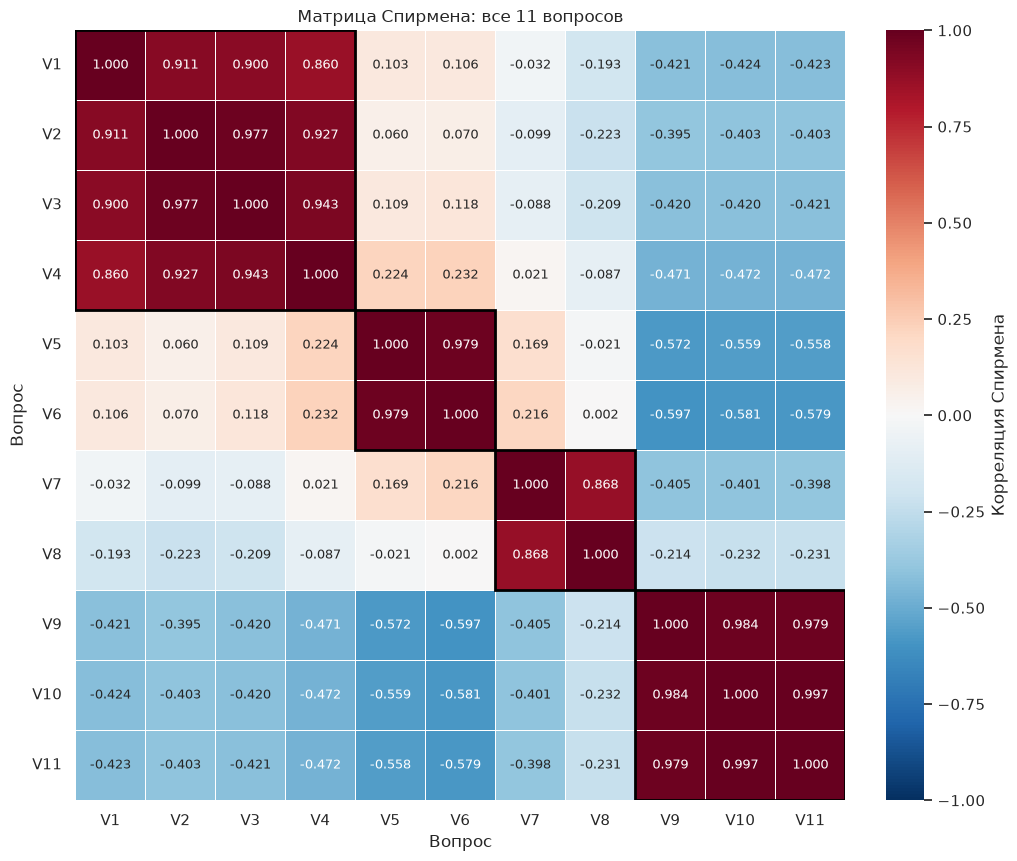

In [6]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(10, 8.5), constrained_layout=True)
sns.heatmap(spearman, annot=True, fmt=".3f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.4,
            annot_kws={"size": 9},
            cbar_kws={"label": "Корреляция Спирмена"}, ax=ax)

# В исходном порядке анкеты вопросы каждой предложенной темы идут подряд.
for columns in themes.values():
    start = data.columns.get_loc(columns[0])
    ax.add_patch(Rectangle((start, start), len(columns), len(columns),
                           fill=False, edgecolor="black", linewidth=2))
ax.set(title="Матрица Спирмена: все 11 вопросов", xlabel="Вопрос", ylabel="Вопрос")
ax.tick_params(axis="both", rotation=0)
plt.show()

На полной матрице видны и связи между темами: оценки самочувствия отрицательно связаны со сладким (ρ от −0,60 до −0,56) и свежестью/уверенностью (от −0,47 до −0,39). Это различия ответов в данной выборке, а не доказательство причинной связи или несовместимости мотивов у отдельного человека.

Внутри предложенных тем корреляции высокие: около 0,86–0,98 для V1–V4, 0,979 для V5–V6, 0,868 для V7–V8 и 0,979–0,997 для V9–V11. Это поддерживает совместное обсуждение этих вопросов: в данной выборке ответы на них обычно меняются согласованно.

Но высокая корреляция **не доказывает**, что вопросы измеряют одну и ту же характеристику, взаимозаменяемы или должны иметь равные веса в общем индексе. Она рассчитана по всей выборке и может частично отражать различия между сегментами. Для обоснования отдельных измерительных шкал потребовалось бы дополнительное исследование анкеты.

Поэтому **среднее между разными вопросами не рассчитываем**. На рисунке ниже каждая ячейка - средний ответ респондентов одного кластера на **один отдельный вопрос**. Так видно, какие именно оценки различаются. Темы остаются только словесными ориентирами; их количество не задаёт число кластеров. Одна тема может объединять несколько разных профилей потребителей.

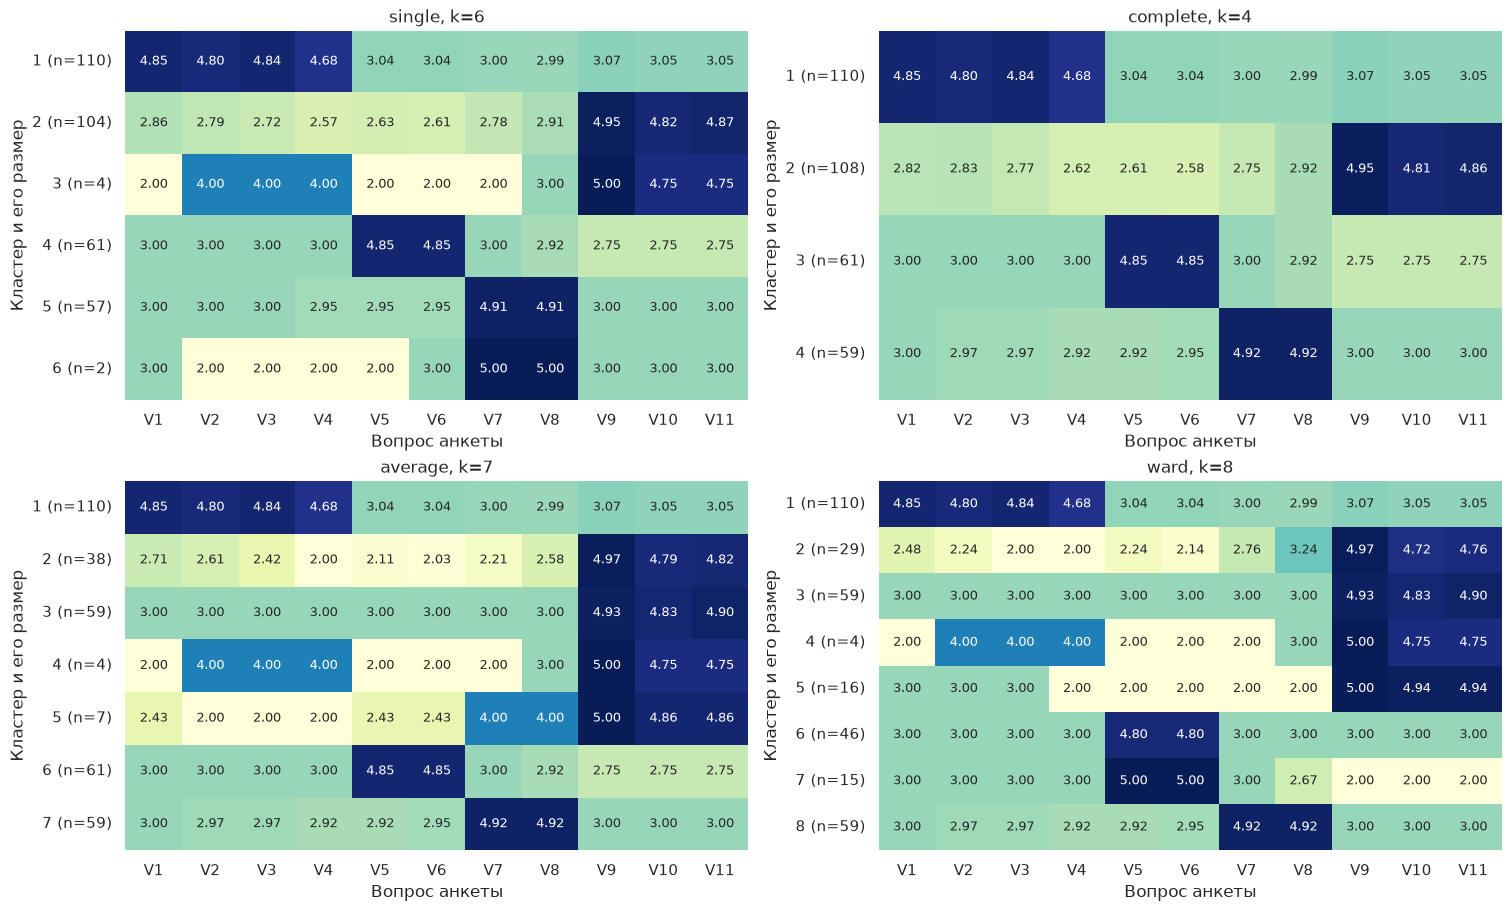

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for method, ax in zip(methods, axes.flat):
    k = int(best_by_method.loc[method, "k"])
    _, candidate_labels = fit_clusters(data, n_clusters=k, method=method)
    candidate_groups = data.assign(Кластер=candidate_labels).groupby("Кластер")
    candidate_means = candidate_groups.mean()
    row_labels = [f"{i} (n={size})" for i, size in candidate_groups.size().items()]
    sns.heatmap(candidate_means, annot=True, fmt=".2f", cmap="YlGnBu", vmin=2, vmax=5,
                yticklabels=row_labels, cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set(title=f"{method}, k={k}", ylabel="Кластер и его размер", xlabel="Вопрос анкеты")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)
plt.show()

На полном профиле видно, почему усреднение вопросов могло бы помешать. У Ward при восьми кластерах группа из четырёх человек имеет V1 = 2, но V2 = V3 = V4 = 4. Общее среднее 3,5 скрыло бы более низкую оценку именно освежения дыхания. У другой группы, из 29 человек, V7 ≈ 2,76 и V8 ≈ 3,24; их среднее равно 3, как у группы из 59 человек с V7 = V8 = 3, хотя ответы различаются.

У complete видны четыре разных ведущих мотива. Average и Ward сохраняют эти крупные различия, но дополнительно выделяют варианты внутри них. Например, у average есть группа из 7 человек, сочетающая высокие оценки самочувствия и концентрации. Такие подгруппы не бессмысленны: они могут быть нужны для более подробного исследования.

### 4. Что дают дополнительные кластеры

В разделе 3 мы сравнили силуэты. Теперь выясним, какие различия стоят за ростом числа групп. Сначала проследим **одно дерево Ward**: его срез на восемь групп дал наибольший силуэт среди всех рассмотренных вариантов. Это повод изучить его подробнее.

Пойдём от двух групп к четырём, затем от четырёх к шести и восьми. При неизменном методе каждый следующий срез только разделяет прежние группы. В конце сравним найденную структуру с complete и average.

In [9]:
def describe_groups(frame, labels):
    """По меткам вернуть средние каждого вопроса и число респондентов n."""
    groups = frame.assign(Кластер=labels).groupby("Кластер")
    profile = groups.mean()
    profile.insert(0, "n", groups.size())
    return profile


def plot_profile(profile, ax, title):
    """Нарисовать профиль со столбцом n; вернуть объект для общей шкалы цвета."""
    row_labels = [f"{i} (n={int(n)})" for i, n in profile["n"].items()]
    sns.heatmap(profile.drop(columns="n"), annot=True, fmt=".2f",
                cmap="YlGnBu", vmin=2, vmax=5, linewidths=0.4,
                yticklabels=row_labels, cbar=False, ax=ax,
                annot_kws={"size": 10})
    ax.set(title=title, xlabel="Вопрос анкеты", ylabel="Группа и её размер")
    ax.tick_params(axis="both", rotation=0)
    return ax.collections[0]


def plot_transitions(stages, ax, title):
    """Схема вложенных разбиений: stages - упорядоченный словарь название → метки.

    Массивы меток относятся к одним и тем же людям в одинаковом порядке.
    Для фрагмента дерева передаём одинаковую подвыборку во всех массивах.
    """
    names = list(stages)
    last = stages[names[-1]]
    # Соседние конечные группы располагаем внутри общей родительской ветви.
    leaf_order = sorted(np.unique(last), key=lambda group: tuple(
        labels[np.flatnonzero(last == group)[0]] for labels in stages.values()
    ))
    leaf_y = {group: len(leaf_order) - 1 - i for i, group in enumerate(leaf_order)}
    positions = {}
    for name, labels_here in stages.items():
        overlap = pd.crosstab(labels_here, last)
        assert ((overlap > 0).sum(axis=0) == 1).all(), "Разбиения должны быть вложены"
        for group, row in overlap.iterrows():
            children = row.index[row > 0]
            positions[(name, group)] = np.mean([leaf_y[child] for child in children])

    for step, (before, after) in enumerate(zip(names[:-1], names[1:])):
        overlap = pd.crosstab(stages[before], stages[after])
        for parent, row in overlap.iterrows():
            for child in row.index[row > 0]:
                ax.plot([step, step + 1],
                        [positions[(before, parent)], positions[(after, child)]],
                        color="#7198ae", lw=1.8, zorder=1)

    for step, name in enumerate(names):
        counts = pd.Series(stages[name]).value_counts()
        for group, count in counts.items():
            ax.text(step, positions[(name, group)], f"Группа {group} · {count} чел.",
                    ha="center", va="center", fontsize=10, zorder=2,
                    bbox=dict(boxstyle="round,pad=0.45", fc="#edf5f7", ec="#3d7089"))
        ax.text(step, len(leaf_order) - 0.15, name, ha="center", weight="bold")
    ax.set(xlim=(-0.5, len(names) - 0.5), ylim=(-0.65, len(leaf_order) + 0.3))
    ax.set_title(title, pad=16)
    ax.axis("off")


# Одно дерево, пять срезов. Оценки силуэта берём из расчётов раздела 3.
ward_tree, _ = fit_clusters(data, n_clusters=2, method="ward")
ward_steps = [2, 3, 4, 6, 8]
ward_labels = {k: cut_tree(ward_tree, n_clusters=[k]).ravel() + 1 for k in ward_steps}
ward_profiles = {k: describe_groups(data, labels_here) for k, labels_here in ward_labels.items()}
ward_scores = results[results["Метод"] == "ward"].set_index("k")["Силуэт"]

**От двух групп к четырём: какие мотивы разделяются?**

Сначала посмотрим на состав групп, затем - на их ответы. Схема охватывает всех 338 человек; числа в конечных ветвях суммируются в размер родительской группы. На картах под ней показаны все 11 вопросов.

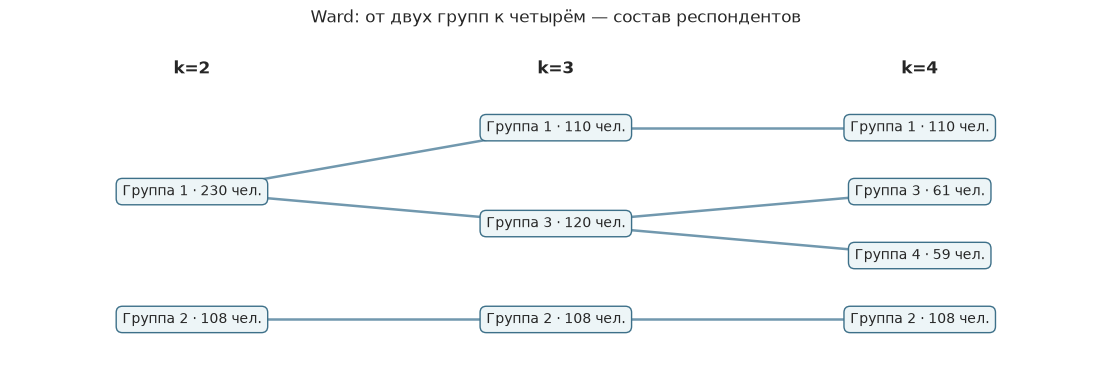

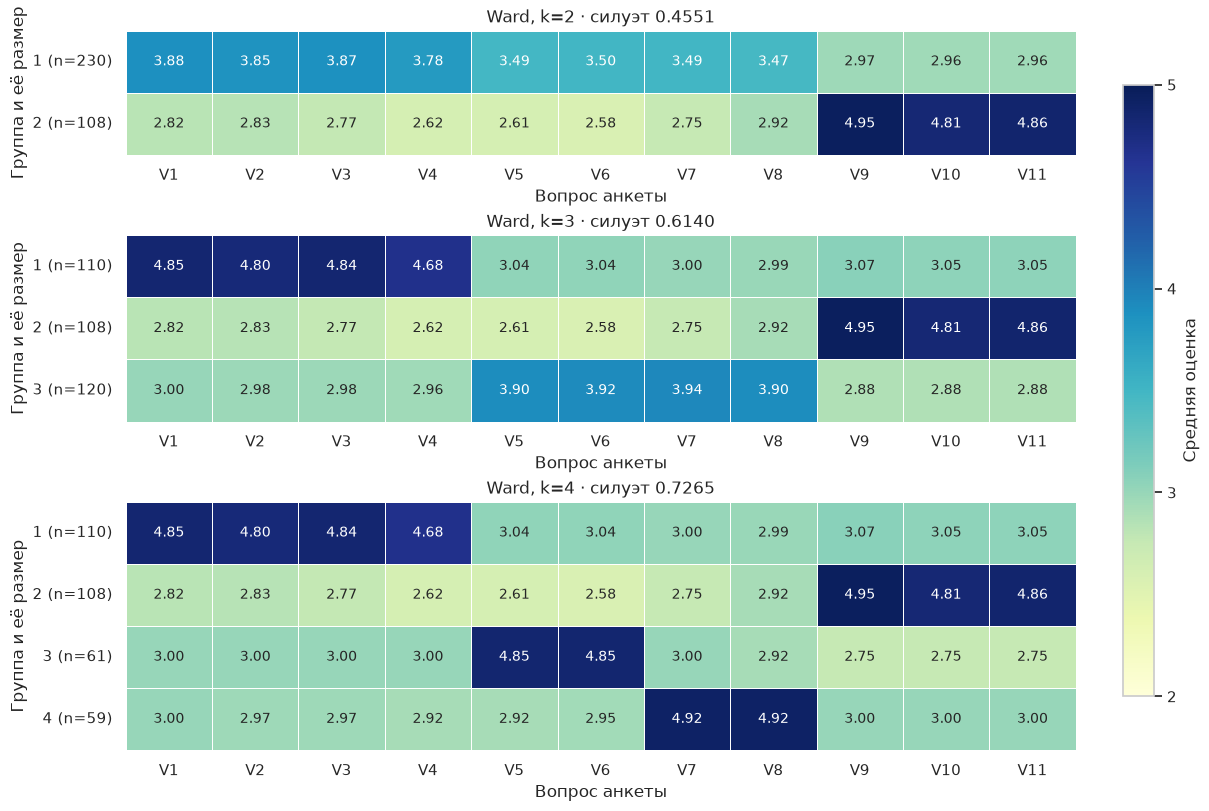

Ward, k=3, группа 3, V5: 468 / 120 = 3.90


In [10]:
fig, ax = plt.subplots(figsize=(11, 3.6), constrained_layout=True)
plot_transitions({f"k={k}": ward_labels[k] for k in [2, 3, 4]}, ax,
                 "Ward: от двух групп к четырём - состав респондентов")
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(12, 8),
                         gridspec_kw={"height_ratios": [2, 3, 4]}, constrained_layout=True)
for k, ax in zip([2, 3, 4], axes):
    color_source = plot_profile(ward_profiles[k], ax,
                                f"Ward, k={k} · силуэт {ward_scores.loc[k]:.4f}")
fig.colorbar(color_source, ax=axes.tolist(), shrink=0.85,
             label="Средняя оценка", ticks=[2, 3, 4, 5])
plt.show()

# Пример происхождения одного числа на карте - среднее V5 в группе из 120 человек.
answers = data.loc[ward_labels[3] == 3, "V5"]
print(f"Ward, k=3, группа 3, V5: {answers.sum()} / {len(answers)} = {answers.mean():.2f}")

**Переход 2 → 3.** Группа из 230 человек делится на **110 + 120**. У 110 человек выделяются V1–V4 (примерно 4,68–4,85): свежесть и уверенность. У 120 человек повышены средние V5–V8 (около 3,90–3,94). Группа самочувствия из 108 человек, с высокими V9–V11, сохраняется. Силуэт растёт с **0,4551 до 0,6140**.

**Переход 3 → 4.** Группа из 120 человек разделяется на **61 + 59**. У 61 человека высоки V5–V6 (4,85), а V7–V8 - около 3: это сладкое. У 59 человек, наоборот, V7–V8 равны примерно 4,92, а V5–V6 - около 2,92–2,95: это концентрация и пауза. Силуэт растёт с **0,6140 до 0,7265**.

Здесь видно, зачем смотреть на состав вместе с профилем. Средние около 3,9 в прежней группе из 120 человек смешивали два разных набора ответов; они не означали, что у каждого человека одинаково выражены оба мотива. Например, значение V5 = 3,90 получилось как **468 / 120**.

Четыре группы позволяют описать эти различия отдельно. Но останавливаться только на этом основании рано: проверим, что дают более подробные срезы.

**От четырёх групп к шести и восьми: какие подтипы появляются?**

Восемь групп - максимум силуэта в нашем сравнении. Шесть берём как промежуточный вариант: после снижения при пяти группах силуэт снова выше, чем при четырёх, а минимальная группа ещё содержит 20 человек. Результаты для пяти и семи групп остаются в общей таблице раздела 3.

Ниже проследим две ветви, которые разделяются после четырёх групп: самочувствие (108 человек) и сладкое (61 человек). Свежесть (110) и концентрация (59) сохраняются целиком. На картах показаны только эти две изменяющиеся ветви; **силуэт в заголовках рассчитан по всем 338 людям**.

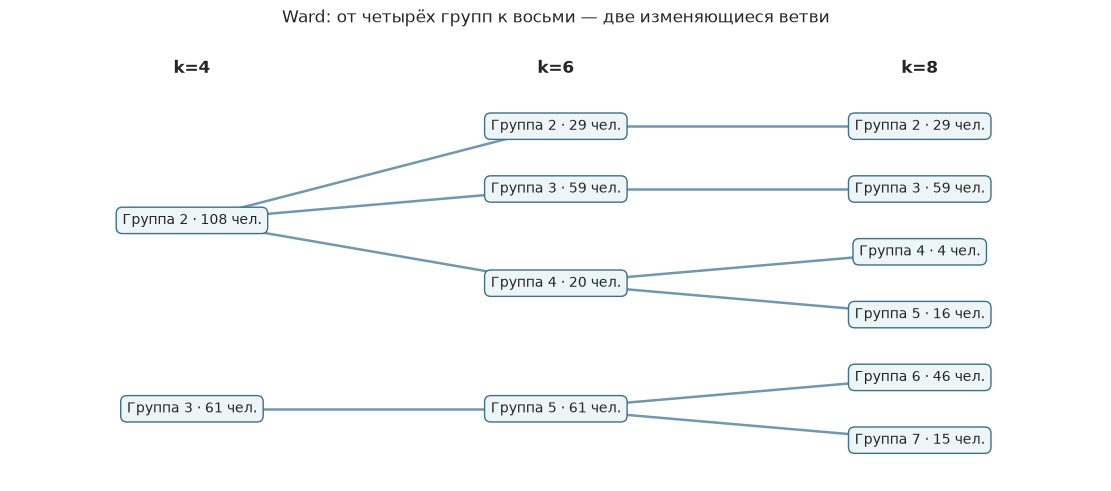

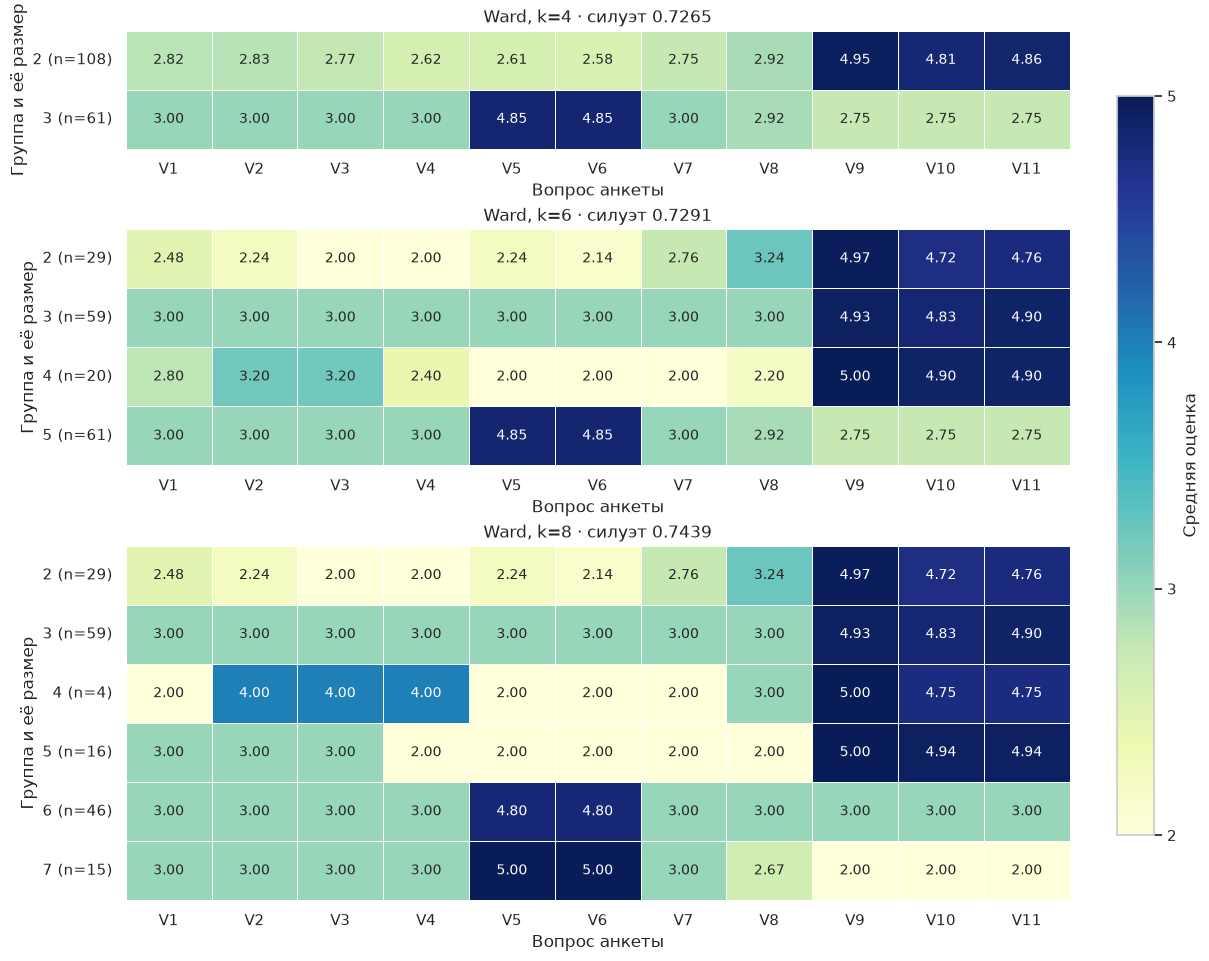

In [11]:
overlap_4_8 = pd.crosstab(ward_labels[4], ward_labels[8])
changed_groups = overlap_4_8.index[(overlap_4_8 > 0).sum(axis=1) > 1]
changed_mask = np.isin(ward_labels[4], changed_groups)

# Фильтр выбирается по фактическому разделению групп, а не по их названиям.
focus_profiles = {
    k: ward_profiles[k].loc[np.unique(ward_labels[k][changed_mask])]
    for k in [4, 6, 8]
}
assert changed_mask.sum() == 169
assert all(profile["n"].sum() == 169 for profile in focus_profiles.values())

fig, ax = plt.subplots(figsize=(11, 4.8), constrained_layout=True)
plot_transitions({f"k={k}": ward_labels[k][changed_mask] for k in [4, 6, 8]}, ax,
                 "Ward: от четырёх групп к восьми - две изменяющиеся ветви")
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(12, 9.5),
                         gridspec_kw={"height_ratios": [2, 4, 6]}, constrained_layout=True)
for k, ax in zip([4, 6, 8], axes):
    color_source = plot_profile(focus_profiles[k], ax,
                                f"Ward, k={k} · силуэт {ward_scores.loc[k]:.4f}")
fig.colorbar(color_source, ax=axes.tolist(), shrink=0.85,
             label="Средняя оценка", ticks=[2, 3, 4, 5])
plt.show()

**Переход 4 → 6.** Только самочувствие разделяется на **29 + 59 + 20 = 108**. По карте видно, чем отличаются эти подгруппы:

- у 59 человек все V1–V8 равны 3;
- у 29 человек V3 = V4 = 2, а V7 и V8 - примерно 2,76 и 3,24;
- у 20 человек V5 = V6 = V7 = 2.

При этом V9–V11 у всех трёх остаются высокими. Значит, разделение уточняет отношение к другим причинам употребления внутри группы самочувствия. Силуэт растёт с **0,7265 до 0,7291** - примерно на 0,0026. Это небольшой прирост, но подгруппы различимы по ответам; отвергать вариант из шести групп просто из-за их размера нельзя.

**Переход 6 → 8.** Происходят два разделения:

- **20 → 4 + 16:** по V1–V4 профили равны **2/4/4/4** и **3/3/3/2**. Это различия в мотивах свежести и уверенности внутри прежней ветви самочувствия.
- **61 → 46 + 15:** V5–V6 равны примерно **4,80 против 5**, а V9–V11 - **3 против 2**. Вторая подгруппа чуть выше оценивает мотивы сладкого и ниже - мотивы самочувствия.

Силуэт растёт с **0,7291 до 0,7439** - примерно на 0,0148. Восемь групп выявляют дополнительные различия, но одна группа содержит всего четыре человека. Её профиль можно описать, однако данных мало для широких маркетинговых выводов о таком сегменте.

**Проверка другими методами.**

Теперь вернёмся к лучшим срезам complete и average из раздела 3. Нужно выяснить, поддерживают ли они найденные крупные различия и какую дополнительную детализацию предлагают.

In [12]:
_, complete_4_labels = fit_clusters(data, n_clusters=4, method="complete")
_, average_4_labels = fit_clusters(data, n_clusters=4, method="average")
_, average_7_labels = fit_clusters(data, n_clusters=7, method="average")

print("Совпадение групп (ARI = 1 означает одинаковый состав):")
print(f"Ward/4 и complete/4: {adjusted_rand_score(ward_labels[4], complete_4_labels):.3f}")
print(f"Ward/4 и average/4:  {adjusted_rand_score(ward_labels[4], average_4_labels):.3f}")

# Проверяем, как average/7 делит те же крупные группы, найденные у Ward/4.
overlap_average = pd.crosstab(ward_labels[4], average_7_labels)
assert ((overlap_average > 0).sum(axis=0) == 1).all()
for group, row in overlap_average.iterrows():
    children = row[row > 0]
    if len(children) > 1:
        parts = " + ".join(f"{int(count)} (группа {child})" for child, count in children.items())
        print(f"Ward/4, группа {group}, {int(row.sum())} человек → average/7: {parts}")

Совпадение групп (ARI = 1 означает одинаковый состав):
Ward/4 и complete/4: 1.000
Ward/4 и average/4:  1.000
Ward/4, группа 2, 108 человек → average/7: 38 (группа 2) + 59 (группа 3) + 4 (группа 4) + 7 (группа 5)


У **complete при четырёх группах** состав полностью совпадает с Ward/4: ARI = 1. Следовательно, профили и их интерпретация те же. При этом для complete четыре группы - его собственный максимум силуэта (0,7265). Average при четырёх группах также подтверждает этот состав.

У **average при семи группах** силуэт выше - 0,7334. Расчёт показывает, что три крупные группы сохраняются, а самочувствие делится на **38 + 59 + 4 + 7 = 108**. Профили этих подгрупп уже видны на карте `average, k=7` в разделе 3. Например, у семи человек V7 = V8 = 4, V9 = 5, V10 = V11 ≈ 4,86: это сочетание концентрации и самочувствия. Такая детализация тоже имеет смысл, хотя для двух подгрупп наблюдений мало.

Итак, мы выбираем **уровень подробности**, а не ищем единственное истинное число групп. Четыре группы дают крупные сегменты с разными ведущими мотивами; шесть уточняют самочувствие; восемь добавляют различия и внутри сладкого. Если главный критерий - силуэт, выбираем **Ward/8**. Для общего описания потребителей в этой работе оставим **четыре крупных сегмента**, сохранив вывод о возможных подтипах. Их одинаковый состав у трёх методов поддерживает такое описание, но не доказывает, что оно единственно правильное.

### 5. Итоговый выбор и интерпретация

Выбираем **Ward и четыре кластера**.

**Почему Ward.** На каждом шаге он выбирает объединение, которое меньше всего увеличивает разброс ответов внутри групп. Это подходит нашей задаче: получить понятные сегменты, которые можно описать общим средним профилем потребностей. Используем евклидово расстояние, как требуется для Ward, и принятое ранее допущение о равных интервалах между оценками.

**Почему четыре группы.** В разделе 4 видно, что при двух и трёх группах ещё смешиваются разные мотивы. Четыре уже разделяют свежесть, самочувствие, сладкое и концентрацию, причём в каждой группе от 59 до 110 человек. Шесть и восемь групп уточняют подтипы внутри этих сегментов. При восьми силуэт выше, но появляется группа всего из четырёх человек. Для общего описания потребителей выбираем четыре крупных сегмента; если ориентироваться только на силуэт, предпочтительнее восемь.

Посмотрим на выбранный срез дерева. **Сначала показаны все 338 респондентов:** каждый лист и цветной штрих внизу - отдельный человек. Четыре цвета обозначают итоговые группы, серые ветви - их дальнейшие объединения выше линии среза.

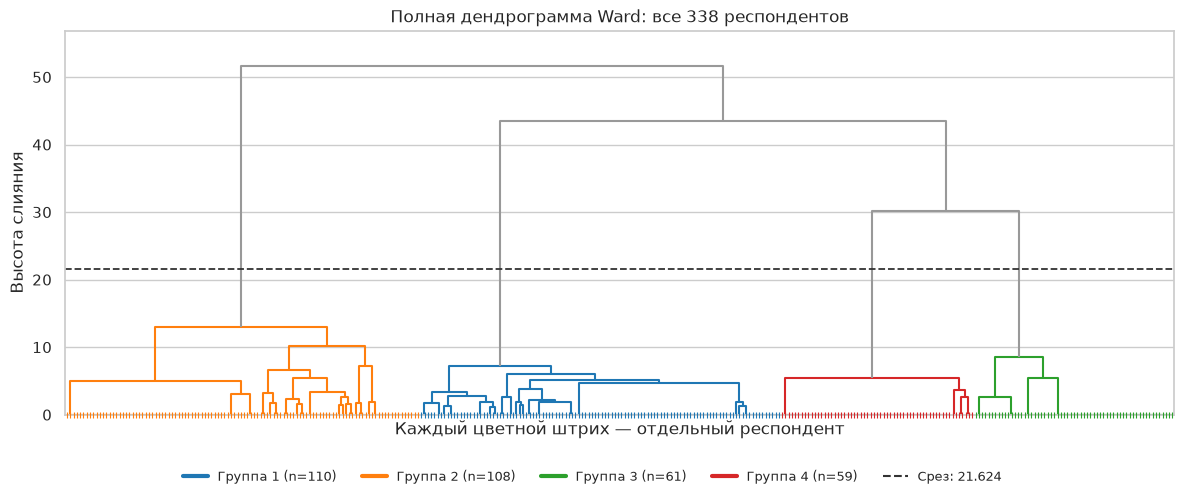

In [13]:
def draw_ward_tree(tree, labels, cut_height, truncate_p=None):
    """Показать дерево с цветами групп; truncate_p задаёт число видимых ветвей.

    None показывает всех респондентов. Цвета определяются по меткам labels
    и сохраняются при сокращении рисунка. Функция выводит график.
    """
    group_ids = np.unique(labels)
    colors = dict(zip(group_ids, sns.color_palette("tab10", len(group_ids)).as_hex()))
    # Ветка окрашена, если все её респонденты принадлежат одной итоговой группе.
    node_group = dict(enumerate(labels))
    for i, merge in enumerate(tree):
        left, right = int(merge[0]), int(merge[1])
        node_group[len(labels) + i] = (node_group[left]
                                      if node_group[left] == node_group[right] else None)

    fig, ax = plt.subplots(figsize=(12, 5))
    options = {} if truncate_p is None else {"truncate_mode": "lastp", "p": truncate_p}
    drawing = dendrogram(
        tree, ax=ax, no_labels=truncate_p is None,
        link_color_func=lambda node: colors.get(node_group[node], "#999999"),
        **options,
    )
    if truncate_p is None:
        # Штрихи показывают и респондентов с полностью одинаковыми ответами.
        leaf_colors = [colors[labels[i]] for i in drawing["leaves"]]
        ax.scatter(5 + 10 * np.arange(len(labels)), np.zeros(len(labels)),
                   c=leaf_colors, marker="|", s=18, linewidths=0.8, clip_on=False, zorder=3)
        title = f"Полная дендрограмма Ward: все {len(labels)} респондентов"
        xlabel = "Каждый цветной штрих - отдельный респондент"
    else:
        title = f"То же дерево Ward: нижние ветви свёрнуты в {truncate_p} поддеревьев"
        xlabel = "В скобках - число респондентов в свёрнутой ветви"
    ax.axhline(cut_height, color="#333333", linestyle="--", linewidth=1.3)
    ax.set(title=title, xlabel=xlabel, ylabel="Высота слияния",
           ylim=(0, tree[-1, 2] * 1.1))
    sizes_here = pd.Series(labels).value_counts()
    handles = [Line2D([0], [0], color=colors[group], lw=3,
                      label=f"Группа {group} (n={sizes_here[group]})") for group in group_ids]
    handles.append(Line2D([0], [0], color="#333333", linestyle="--",
                          label=f"Срез: {cut_height:.3f}"))
    fig.legend(handles=handles, loc="lower center", ncols=len(handles),
               frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    plt.show()


chosen_method = "ward"
n_clusters = 4
Z, labels = fit_clusters(data, n_clusters=n_clusters, method=chosen_method)
lower = Z[len(data) - n_clusters - 1, 2]
upper = Z[len(data) - n_clusters, 2]
cut_height = (lower + upper) / 2

# Итоговые характеристики для интерпретации и проверки в разделе 6.
grouped = data.assign(Кластер=labels).groupby("Кластер")
means, medians, sizes = grouped.mean(), grouped.median(), grouped.size()
shares = sizes / len(data) * 100

draw_ward_tree(Z, labels, cut_height)

Теперь свернём нижнюю часть **того же дерева** в 12 поддеревьев, чтобы крупные объединения было легче рассмотреть. Числа в скобках показывают, сколько человек скрыто в каждой ветви. Число 12 меняет только подробность рисунка: итоговых кластеров по-прежнему четыре.

Цвета, высоты и линия среза на обоих графиках одинаковы.

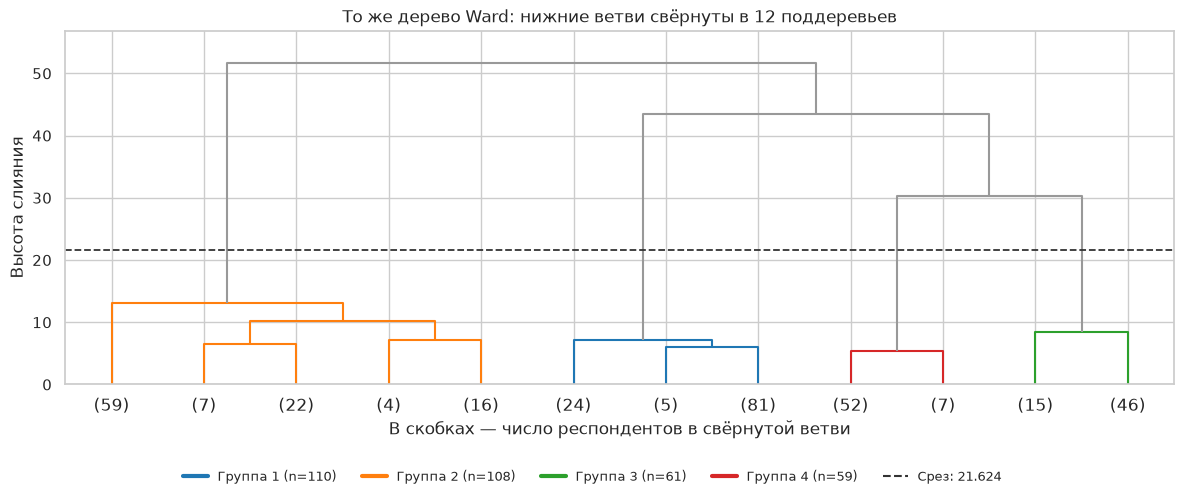

In [14]:
draw_ward_tree(Z, labels, cut_height, truncate_p=12)

Линия среза пересекает четыре крупные ветви. При переходе от четырёх групп к трём высота слияния заметно возрастает: объединяются уже различающиеся профили сладкого и концентрации. Это дополнительно поддерживает выбор, сделанный по результатам раздела 4.

**Содержательный результат:**


- **Свежесть и уверенность - 110 человек (32,54%).** Высоки V1–V4. Леденцы связывают со свежестью дыхания, ощущениями во рту и уверенностью.
- **Самочувствие - 108 человек (31,95%).** Высоки V9–V11: горло, нос и общее самочувствие.
- **Сладкое - 61 человек (18,05%).** Высоки V5–V6: желание сладкого и замена других кондитерских изделий.
- **Концентрация и пауза - 59 человек (17,46%).** Высоки V7–V8: возможность сосредоточиться или ненадолго отвлечься и подумать.

Медианы по перечисленным ведущим вопросам равны 5, по остальным - 3. Это подтверждает характерные различия, показанные средними профилями выше. Сегменты дают направления для дальнейшего изучения потребностей и коммуникации продукта; предпочтения марок и коммерческую привлекательность по этой анкете установить нельзя.

### 6. Выводы и ограничения

В завершение проверим распределение респондентов по группам и влияние стандартизации.

In [15]:
scaled_data = StandardScaler().fit_transform(data)
_, scaled_labels = fit_clusters(scaled_data, n_clusters=n_clusters, method=chosen_method)
print("ARI после стандартизации:", adjusted_rand_score(labels, scaled_labels))

assert sizes.sum() == len(data)
assert len(np.unique(labels)) == n_clusters
print(f"Все {len(data)} респондентов распределены по {n_clusters} группам.")

ARI после стандартизации: 1.0
Все 338 респондентов распределены по 4 группам.


В работе методом **Ward** выделены **четыре сегмента**: свежесть и уверенность, самочувствие, сладкое, концентрация и пауза. В разбиение вошли все **338 респондентов**. После стандартизации состав групп не изменился (**ARI = 1**). Результат описывает основные мотивы употребления леденцов в этой выборке.

Число кластеров может меняться в зависимости от задачи, поставленной бизнесом/заказчиком. В данном случае мы остановились на крупных сегментах, с точки зрения причин потребления продукта, но если планируются какие-то маркетинговые активности или требуюется иной подход к анализу респондентов, число групп может юыть изменено.

**Ограничения:** оценки имеют порядковую шкалу, хотя в расчётах приняты равные интервалы между баллами. Связанные вопросы могут усиливать вклад отдельных мотивов.